# Изучение развития игровой индустрии в ХХ веке

**Автор: Казаков Александр**  
**Дата: 23.10.2026**   

## 0.1 Цели и задачи проекта

Цель проета создать готовые данные для написания статьи о том, как развивалась игровая индустрия в 20 веке.

## 0.2 Описание данных

Данные new_games.csv содержат информацию о продажах игр разных жанров и платформ, а также пользовательские и экспертные оценки игр:

* **Name** — Название игры
* **Platform** — Название платформы
* **Year of Release** — Год выпуска игры
* **Genre** — Жанр игры
* **NA sales** — Продажи в Северной Америке (в миллионах проданных копий)
* **EU sales** — Продажи в Европе (в миллионах проданных копий)
* **JP sales** — Продажи в Японии (в миллионах проданных копий)
* **Other sales** — Продажи в других странах (в миллионах проданных копий)
* **Critic Score** — Оценка критиков (от 0 до 100)
* **User Score** — Оценка пользователей (от 0 до 10)
* **Rating** — Рейтинг организации ESRB (англ. Entertainment Software Rating Board). Эта ассоциация определяет рейтинг компьютерных игр и присваивает им подходящую возрастную категорию

## 0.3 Содержимое проекта
## Знакомство с данными
    * Проверить их корректность
    * Провести предобработку:
      * Приведение данных к необходимым типам данных
      * Обработка пропусков
      * Избавление от дубликатов
    * Получить необходимые срезы
    * Отфильтровать данные
    * Категоризировать данные
    * Выделить топ платформ


# 1. Загрузка данных и знакомство с ними


In [1]:
# Импорт библиотек
import pandas as pd

# Загрузка данных
df = pd.read_csv('new_games.csv')

Познакомьтесь с данными: выведите первые строки и результат метода `info()`.

In [2]:
# Первые строки датафрейма
df.head()

,Name,Platform,Year of Release,Genre,NA sales,EU sales,JP sales,Other sales,Critic Score,User Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [3]:
# Информация о датафрейме
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16956 entries, 0 to 16955
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16954 non-null  object 
 1   Platform         16956 non-null  object 
 2   Year of Release  16681 non-null  float64
 3   Genre            16954 non-null  object 
 4   NA sales         16956 non-null  float64
 5   EU sales         16956 non-null  object 
 6   JP sales         16956 non-null  object 
 7   Other sales      16956 non-null  float64
 8   Critic Score     8242 non-null   float64
 9   User Score       10152 non-null  object 
 10  Rating           10085 non-null  object 
dtypes: float64(4), object(7)
memory usage: 1.4+ MB


**Вывод о полученных данных:**

Всего в датафрейме храниться информация о 11 столбцов, в которых 7 имеют тип Object и 4 столбца имеют тип float64. В данных встречаются пропуски, наибольшее содержание находится в столбце 'Critic Score', а также 'User Score' и 'Rating'.

# 2. Проверка ошибок в данных и их предобработка

## 2.1. Названия, или метки, столбцов датафрейма

Приведение наименования колонок к стилю snake case

In [4]:
# Названия столбцов до преобразования
display(df.columns.to_frame(index=False))

,0
0,Name
1,Platform
2,Year of Release
3,Genre
4,NA sales
5,EU sales
6,JP sales
7,Other sales
8,Critic Score
9,User Score


In [5]:
df.columns = df.columns.str.lower().str.replace(' ','_')
display(df.columns.to_frame(index=False))

,0
0,name
1,platform
2,year_of_release
3,genre
4,na_sales
5,eu_sales
6,jp_sales
7,other_sales
8,critic_score
9,user_score


## 2.2. Типы данных

В данных встречаются не верные типы данных, например для стобцов: eu_sales, jp_sales, user_score. Лучше было бы присвоить им значние float64, потому что значения содержат только числа. 

In [6]:
df.dtypes

name                object
platform            object
year_of_release    float64
genre               object
na_sales           float64
eu_sales            object
jp_sales            object
other_sales        float64
critic_score       float64
user_score          object
rating              object
dtype: object

Приведение столбцов к числовому типу данных.

In [7]:
# Замена строковых значений на пропуски и приведение к числовому типу

df['year_of_release'] = df['year_of_release'].astype('int', errors = 'ignore')
df['eu_sales'] = pd.to_numeric(df['eu_sales'], errors = 'coerce')
df['jp_sales'] = pd.to_numeric(df['jp_sales'], errors = 'coerce')
df['user_score'] = pd.to_numeric(df['user_score'], errors = 'coerce')
df.dtypes

name                object
platform            object
year_of_release    float64
genre               object
na_sales           float64
eu_sales           float64
jp_sales           float64
other_sales        float64
critic_score       float64
user_score         float64
rating              object
dtype: object

## 2.3. Наличие пропусков в данных


In [8]:
missing = round(df.isna().sum() / len(df) * 2, 2)
mis_df = pd.DataFrame({
    'Кол-во пропусков': df.isna().sum(),
    'Процент пропусков (%)' : missing
})
print('\nАнализ пропушенных значений:')
display(mis_df)


Анализ пропушенных значений:


,Кол-во пропусков,Процент пропусков (%)
name,2,0.00
platform,0,0.00
year_of_release,275,0.03
genre,2,0.00
na_sales,0,0.00
eu_sales,6,0.00
jp_sales,4,0.00
other_sales,0,0.00
critic_score,8714,1.03
user_score,9268,1.09


**Промежуточный вывод по пропускам:**

Данные у которых пропуски менее 2% такие как 'name', 'genre' и 'year_of_release' будет логичнее просто удалить, остальные численные значения: 'eu_sales','jp_sales', 'user_score' будет необходимо заменить на среднее значение(по жанру). Пропуски в столбце 'rating' остаются, потому что в дальшнем иследовании они не используются. Столбец 'critic_score' заменить на индиактор(-1, так как его быть не может)


In [9]:
df['eu_sales'] = df['eu_sales'].fillna(df['eu_sales'].mean())
df['jp_sales'] = df['jp_sales'].fillna(df['jp_sales'].mean())
df['user_score'] = df['user_score'].fillna(-1)
df['critic_score'] = df['critic_score'].fillna(-1)

In [10]:
df = df.dropna(subset= ['name'])
df = df.dropna(subset= ['genre'])
df = df.dropna(subset= ['year_of_release'])

df['year_of_release'] = df['year_of_release'].astype('int') # ранее этого сделать было нельзя
df['critic_score'] = df['critic_score'].astype('int') # ранее этого сделать было нельзя
print(round(df.isna().mean() * 100,2))

name                0.00
platform            0.00
year_of_release     0.00
genre               0.00
na_sales            0.00
eu_sales            0.00
jp_sales            0.00
other_sales         0.00
critic_score        0.00
user_score          0.00
rating             40.64
dtype: float64


## 2.4. Явные и неявные дубликаты в данных


In [11]:
# Уникальные значения в категориальных столбцах
print(f'name: {df['name'].unique()}')
print(f'platform : {df['platform'].unique()}')
print(f'rating {df['rating'].unique()}')
print(f'genre {df['genre'].unique()}')
print(f'year_of_release {df['year_of_release'].unique()}')

name: ['Wii Sports' 'Super Mario Bros.' 'Mario Kart Wii' ...
 'Woody Woodpecker in Crazy Castle 5' 'LMA Manager 2007'
 'Haitaka no Psychedelica']
platform : ['Wii' 'NES' 'GB' 'DS' 'X360' 'PS3' 'PS2' 'SNES' 'GBA' 'PS4' '3DS' 'N64'
 'PS' 'XB' 'PC' '2600' 'PSP' 'XOne' 'WiiU' 'GC' 'GEN' 'DC' 'PSV' 'SAT'
 'SCD' 'WS' 'NG' 'TG16' '3DO' 'GG' 'PCFX']
rating ['E' nan 'M' 'T' 'E10+' 'K-A' 'AO' 'EC' 'RP']
genre ['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy' 'MISC'
 'ROLE-PLAYING' 'RACING' 'ACTION' 'SHOOTER' 'FIGHTING' 'SPORTS' 'PLATFORM'
 'ADVENTURE' 'SIMULATION' 'PUZZLE' 'STRATEGY']
year_of_release [2006 1985 2008 2009 1996 1989 1984 2005 1999 2007 2010 2013 2004 1990
 1988 2002 2001 2011 1998 2015 2012 2014 1992 1997 1993 1994 1982 2016
 2003 1986 2000 1995 1991 1981 1987 1980 1983]


In [12]:
# Нормализация текстовых значений
df['genre'] = df['genre'].str.lower()
print(f'genre {df['genre'].unique()}')

genre ['sports' 'platform' 'racing' 'role-playing' 'puzzle' 'misc' 'shooter'
 'simulation' 'action' 'fighting' 'adventure' 'strategy']


Проверка на наличие явных дубликатов.

In [13]:
# Проверка явных дубликатов
df.duplicated().sum()

235

In [14]:
# Удаление дубликатов
df = df.drop_duplicates().reset_index(drop=True)
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16444 entries, 0 to 16443
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16444 non-null  object 
 1   platform         16444 non-null  object 
 2   year_of_release  16444 non-null  int32  
 3   genre            16444 non-null  object 
 4   na_sales         16444 non-null  float64
 5   eu_sales         16444 non-null  float64
 6   jp_sales         16444 non-null  float64
 7   other_sales      16444 non-null  float64
 8   critic_score     16444 non-null  int32  
 9   user_score       16444 non-null  float64
 10  rating           9768 non-null   object 
dtypes: float64(5), int32(2), object(4)
memory usage: 1.3+ MB
None


**Промежуточный вывод по дубликатам:**

Промежуточный вывод: Найдено 235 явных дубликатов, они были удалены. Всего было удаленно 512 строк, из которых 277 строк с пропушенными значениями и 235 явных дубликатов. Что состовляет 3% от общего кол-ва значений.


Данные были очишенны от пропусков и дубликатов, неявных дубликтов небыло замеченно, после всех преобрахований изначальаня выборка изменилась по кол-ву строк на 3%

# 3. Фильтрация данных


In [15]:
# Фильтрация данных по году выпуска
df = df[(df['year_of_release'] >= 2000) & (df['year_of_release'] <= 2013)]
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006,sports,41.36,28.96,3.77,8.45,76,8.0,E
2,Mario Kart Wii,Wii,2008,racing,15.68,12.76,3.79,3.29,82,8.3,E
3,Wii Sports Resort,Wii,2009,sports,15.61,10.93,3.28,2.95,80,8.0,E
6,New Super Mario Bros.,DS,2006,platform,11.28,9.14,6.50,2.88,89,8.5,E
7,Wii Play,Wii,2006,misc,13.96,9.18,2.93,2.84,58,6.6,E


# 4. Категоризация данных

In [16]:
# Категоризация по оценкам пользователей
df_act = df.copy()
df_act['user_score_category'] = pd.cut(df_act['user_score'], bins=[-2,0,3,8,10], labels=['нет оценки','низкая оценка','средняя оценка','высокая оценка'], right=False)

df_act.head(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,user_score_category
0,Wii Sports,Wii,2006,sports,41.36,28.96,3.77,8.45,76,8.0,E,высокая оценка
2,Mario Kart Wii,Wii,2008,racing,15.68,12.76,3.79,3.29,82,8.3,E,высокая оценка
3,Wii Sports Resort,Wii,2009,sports,15.61,10.93,3.28,2.95,80,8.0,E,высокая оценка
6,New Super Mario Bros.,DS,2006,platform,11.28,9.14,6.50,2.88,89,8.5,E,высокая оценка
7,Wii Play,Wii,2006,misc,13.96,9.18,2.93,2.84,58,6.6,E,средняя оценка
8,New Super Mario Bros. Wii,Wii,2009,platform,14.44,6.94,4.70,2.24,87,8.4,E,высокая оценка
10,Nintendogs,DS,2005,simulation,9.05,10.95,1.93,2.74,-1,-1.0,NaN,нет оценки
11,Mario Kart DS,DS,2005,racing,9.71,7.47,4.13,1.90,91,8.6,E,высокая оценка
13,Wii Fit,Wii,2007,sports,8.92,8.03,3.60,2.15,80,7.7,E,средняя оценка
14,Kinect Adventures!,X360,2010,misc,15.00,4.89,0.24,1.69,61,6.3,E,средняя оценка


In [17]:
# Категоризация по оценкам критиков
def critic_categ(item):
    if item > 0 and item  < 30:
        return  'низкая оценка'
    elif item > 30 and item < 80:
        return 'средняя оценка'
    elif item > 80 and item <= 100:
        return 'высокая оценка'
    else: return 'нет оценки'

df_act['critic_score_category'] = df_act['critic_score'].apply(critic_categ)
print(df_act.head())

                    name platform  year_of_release     genre  na_sales  \
0             Wii Sports      Wii             2006    sports     41.36   
2         Mario Kart Wii      Wii             2008    racing     15.68   
3      Wii Sports Resort      Wii             2009    sports     15.61   
6  New Super Mario Bros.       DS             2006  platform     11.28   
7               Wii Play      Wii             2006      misc     13.96   

   eu_sales  jp_sales  other_sales  critic_score  user_score rating  \
0     28.96      3.77         8.45            76         8.0      E   
2     12.76      3.79         3.29            82         8.3      E   
3     10.93      3.28         2.95            80         8.0      E   
6      9.14      6.50         2.88            89         8.5      E   
7      9.18      2.93         2.84            58         6.6      E   

  user_score_category critic_score_category  
0      высокая оценка        средняя оценка  
2      высокая оценка        высокая

Проверка результата

In [18]:
# Количество игр по категориям пользовательских оценок
df_act.groupby('user_score_category', observed=True)['name'].count() # observed=True - это мне дип сик сказал сделать, что бы ошибка не вылезала 

user_score_category
нет оценки        6298
низкая оценка      116
средняя оценка    4081
высокая оценка    2286
Name: name, dtype: int64

In [19]:
# Количество игр по категориям оценок критиков
df_act.groupby('critic_score_category')['name'].count()

critic_score_category
высокая оценка    1489
нет оценки        5827
низкая оценка       55
средняя оценка    5410
Name: name, dtype: int64

Выделение топ-7 платформ по количеству игр, выпущенных за весь актуальный период.

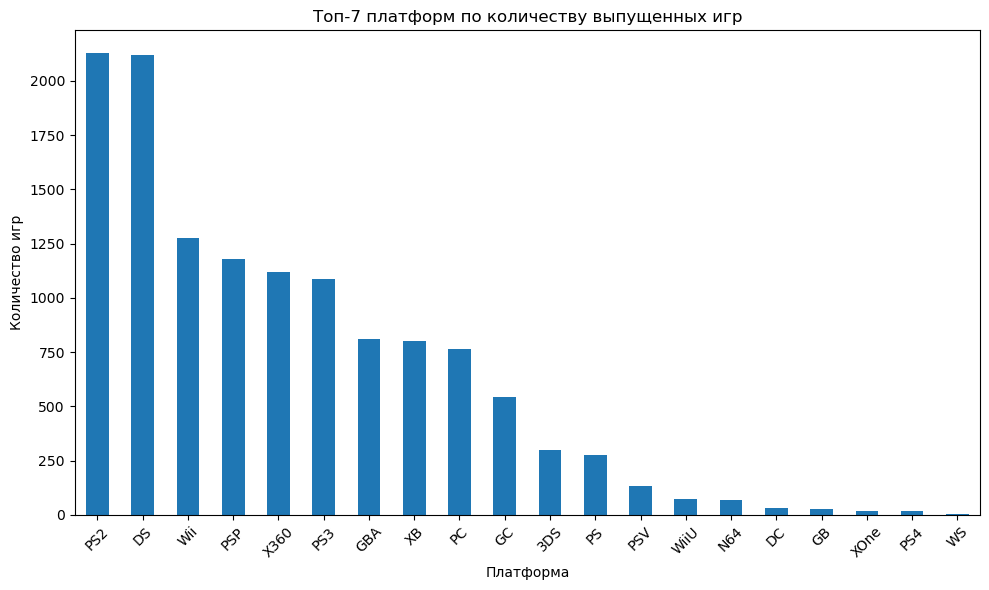

In [20]:
import matplotlib.pyplot as plt

top_platforms = df_act.groupby('platform')['name'].count().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
top_platforms.plot(kind='bar') 
plt.title('Топ-7 платформ по количеству выпущенных игр')
plt.xlabel('Платформа')
plt.ylabel('Количество игр')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 5. Итоговый вывод

В рамках проекта была проведена работа по подготовке данных, фильтрации данных, категоризации данных и выделению топа. При подготовке была произведена очистка данных от пропусков, от явных повторов. В рамках очистки данных от пропусков, было удаленно 277 строк, в строках 'user_score' и 'critic_score' пропуски были заменены значения '-1'. Столбец 'rating' практически никак не обрабатывался, потому что в дальнейшем он не использовался для анализа. На основе этих значений появилась категория 'нет оценки'. Также было удаленно 235 явных повторов. Далее была проведела фильтрация данных по дате выпуска игры с 2000 по 2013. После чего на основе данных было добавленно два новых столбца 'user_score_category' и 'critic_score_category', которых хранят в себе разбитые по категориям оценки критиков и пользователей. И в конце выведенны в порядке убывани кол-во игр и платформы, под которые они были созданы.
